In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/drishyatomar/glowmix-merged-facial-skincare-dataset/PAD-UFES-20/metadata.csv
/kaggle/input/datasets/drishyatomar/glowmix-merged-facial-skincare-dataset/PAD-UFES-20/imgs_part_1/imgs_part_1/PAT_492_937_958.png
/kaggle/input/datasets/drishyatomar/glowmix-merged-facial-skincare-dataset/PAD-UFES-20/imgs_part_1/imgs_part_1/PAT_13_21_350.png
/kaggle/input/datasets/drishyatomar/glowmix-merged-facial-skincare-dataset/PAD-UFES-20/imgs_part_1/imgs_part_1/PAT_456_887_499.png
/kaggle/input/datasets/drishyatomar/glowmix-merged-facial-skincare-dataset/PAD-UFES-20/imgs_part_1/imgs_part_1/PAT_15_1001_749.png
/kaggle/input/datasets/drishyatomar/glowmix-merged-facial-skincare-dataset/PAD-UFES-20/imgs_part_1/imgs_part_1/PAT_456_888_961.png
/kaggle/input/datasets/drishyatomar/glowmix-merged-facial-skincare-dataset/PAD-UFES-20/imgs_part_1/imgs_part_1/PAT_158_621_68.png
/kaggle/input/datasets/drishyatomar/glowmix-merged-facial-skincare-dataset/PAD-UFES-20/imgs_part_1/imgs_part_1/PAT_48

# audit the structure

In [2]:
import os

for dirname, _, filenames in os.walk("/kaggle/input"):
    print(f"\nFolder: {dirname}")
    print(f"Number of files: {len(filenames)}")
    print("First 10 files:")
    for f in filenames[:10]:
        print("  ", f)


Folder: /kaggle/input
Number of files: 0
First 10 files:

Folder: /kaggle/input/datasets
Number of files: 0
First 10 files:

Folder: /kaggle/input/datasets/drishyatomar
Number of files: 0
First 10 files:

Folder: /kaggle/input/datasets/drishyatomar/glowmix-merged-facial-skincare-dataset
Number of files: 0
First 10 files:

Folder: /kaggle/input/datasets/drishyatomar/glowmix-merged-facial-skincare-dataset/PAD-UFES-20
Number of files: 1
First 10 files:
   metadata.csv

Folder: /kaggle/input/datasets/drishyatomar/glowmix-merged-facial-skincare-dataset/PAD-UFES-20/imgs_part_1
Number of files: 0
First 10 files:

Folder: /kaggle/input/datasets/drishyatomar/glowmix-merged-facial-skincare-dataset/PAD-UFES-20/imgs_part_1/imgs_part_1
Number of files: 911
First 10 files:
   PAT_492_937_958.png
   PAT_13_21_350.png
   PAT_456_887_499.png
   PAT_15_1001_749.png
   PAT_456_888_961.png
   PAT_158_621_68.png
   PAT_48_74_309.png
   PAT_88_133_64.png
   PAT_460_893_307.png
   PAT_386_1554_455.png

Fold

In [3]:
from pathlib import Path
from collections import Counter
import os

ROOT = Path("/kaggle/input/datasets/drishyatomar/glowmix-merged-facial-skincare-dataset")

image_exts = {".jpg", ".jpeg", ".png", ".webp", ".bmp"}

print("SOURCE-LEVEL IMAGE COUNTS")
print("=" * 70)

for folder in sorted(ROOT.iterdir()):
    if not folder.is_dir():
        continue

    count = 0

    for p in folder.rglob("*"):
        if p.is_file() and p.suffix.lower() in image_exts:
            count += 1

    print(f"{folder.name:<55} {count:>6}")

SOURCE-LEVEL IMAGE COUNTS
4788-images-Human-Facial-Skin-Defects-Data-main              5
PAD-UFES-20                                               2298
Skin Issues Dataset                                       9770
fitzpatrick17k-main                                          0
scin-main                                                    0


# Skin Issues Dataset audit

In [4]:
from pathlib import Path
from collections import Counter

SKIN_V2 = ROOT / "Skin Issues Dataset" / "Skin v2"

image_exts = {".jpg", ".jpeg", ".png", ".webp", ".bmp"}

class_counts = {}

for folder in sorted(SKIN_V2.iterdir()):
    if folder.is_dir():
        count = sum(
            1 for p in folder.rglob("*")
            if p.is_file() and p.suffix.lower() in image_exts
        )
        class_counts[folder.name] = count

print("SKIN V2 CLASS DISTRIBUTION")
print("=" * 60)

total = 0

for cls, count in class_counts.items():
    print(f"{cls:<45} {count:>6}")
    total += count

print("=" * 60)
print(f"{'TOTAL':<45} {total:>6}")

SKIN V2 CLASS DISTRIBUTION
acne                                            2060
blackheades                                     1970
dark spots                                      2126
pores                                           1632
wrinkles                                        1982
TOTAL                                           9770


# image integrity + dimensions

In [5]:
from PIL import Image
from pathlib import Path
from collections import Counter
import pandas as pd

records = []
corrupted = []

image_exts = {".jpg", ".jpeg", ".png", ".webp", ".bmp"}

for class_dir in sorted(SKIN_V2.iterdir()):
    if not class_dir.is_dir():
        continue

    for img_path in class_dir.rglob("*"):
        if img_path.suffix.lower() not in image_exts:
            continue

        try:
            with Image.open(img_path) as img:
                width, height = img.size
                img.verify()

            records.append({
                "class": class_dir.name,
                "file": img_path.name,
                "path": str(img_path),
                "width": width,
                "height": height,
                "format": img_path.suffix.lower(),
                "file_size_kb": img_path.stat().st_size / 1024,
                "aspect_ratio": width / height
            })

        except Exception as e:
            corrupted.append({
                "class": class_dir.name,
                "file": img_path.name,
                "path": str(img_path),
                "error": str(e)
            })

df = pd.DataFrame(records)
corrupted_df = pd.DataFrame(corrupted)

print("IMAGE INTEGRITY + DIMENSION AUDIT")
print("=" * 60)
print(f"Images processed : {len(df)}")
print(f"Corrupted images : {len(corrupted_df)}")
print(f"Total files      : {len(df) + len(corrupted_df)}")

print("\nDimensions:")
print(df[["width", "height"]].describe())

print("\nFormats:")
print(df["format"].value_counts())

print("\nAspect ratio:")
print(df["aspect_ratio"].describe())

IMAGE INTEGRITY + DIMENSION AUDIT
Images processed : 9770
Corrupted images : 0
Total files      : 9770

Dimensions:
             width       height
count  9770.000000  9770.000000
mean    651.083930   630.183112
std     330.553539   327.538876
min      80.000000    83.000000
25%     640.000000   474.000000
50%     640.000000   640.000000
75%     640.000000   640.000000
max    6720.000000  4480.000000

Formats:
format
.jpg    9770
Name: count, dtype: int64

Aspect ratio:
count    9770.000000
mean        1.055629
std         0.203157
min         0.460417
25%         1.000000
50%         1.000000
75%         1.000000
max         3.870647
Name: aspect_ratio, dtype: float64


# Exact duplicates within GlowMix

In [6]:
import hashlib
from collections import defaultdict
from pathlib import Path

hash_groups = defaultdict(list)

for img_path in SKIN_V2.rglob("*"):
    if not img_path.is_file():
        continue

    if img_path.suffix.lower() not in image_exts:
        continue

    sha = hashlib.sha256()

    with open(img_path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            sha.update(chunk)

    hash_groups[sha.hexdigest()].append(str(img_path))

duplicate_groups = {
    h: files
    for h, files in hash_groups.items()
    if len(files) > 1
}

duplicate_images = sum(len(files) for files in duplicate_groups.values())

print("EXACT DUPLICATE AUDIT")
print("=" * 60)
print(f"Total images              : {len(hash_groups)} unique hashes")
print(f"Duplicate groups          : {len(duplicate_groups)}")
print(f"Images involved           : {duplicate_images}")
print(f"Unique images after dedup : {len(hash_groups)}")

EXACT DUPLICATE AUDIT
Total images              : 9463 unique hashes
Duplicate groups          : 283
Images involved           : 590
Unique images after dedup : 9463


In [7]:
from collections import defaultdict, Counter
from pathlib import Path

duplicate_class_info = []

for files in duplicate_groups.values():
    classes = []

    for file in files:
        p = Path(file)
        # Skin v2 structure: Skin v2/<class>/<image>
        classes.append(p.parent.name)

    duplicate_class_info.append(classes)

same_class_groups = 0
cross_class_groups = 0

for classes in duplicate_class_info:
    if len(set(classes)) == 1:
        same_class_groups += 1
    else:
        cross_class_groups += 1

print("DUPLICATE GROUP CLASS ANALYSIS")
print("=" * 60)
print(f"Duplicate groups       : {len(duplicate_groups)}")
print(f"Same-class groups      : {same_class_groups}")
print(f"Cross-class groups     : {cross_class_groups}")

print("\nClass combinations:")
combo_counts = Counter()

for classes in duplicate_class_info:
    combo = tuple(sorted(classes))
    combo_counts[combo] += 1

for combo, count in combo_counts.most_common():
    print(f"{combo}: {count}")

DUPLICATE GROUP CLASS ANALYSIS
Duplicate groups       : 283
Same-class groups      : 283
Cross-class groups     : 0

Class combinations:
('blackheades', 'blackheades'): 103
('pores', 'pores'): 81
('dark spots', 'dark spots'): 61
('dark spots', 'dark spots', 'dark spots'): 24
('wrinkles', 'wrinkles'): 14


# Near-Duplicate Analysis

In [8]:
from PIL import Image
import imagehash
from pathlib import Path
from collections import defaultdict

phash_groups = defaultdict(list)

image_paths = [
    p for p in SKIN_V2.rglob("*")
    if p.is_file() and p.suffix.lower() in image_exts
]

print(f"Processing {len(image_paths)} images...")

for i, img_path in enumerate(image_paths):

    try:
        with Image.open(img_path) as img:
            h = imagehash.phash(img)

        phash_groups[str(h)].append(str(img_path))

    except Exception:
        pass

    if (i + 1) % 1000 == 0:
        print(f"Processed {i + 1}/{len(image_paths)}")

print("\nP-HASH ANALYSIS")
print("=" * 60)

unique_phashes = len(phash_groups)

duplicate_groups = {
    h: files
    for h, files in phash_groups.items()
    if len(files) > 1
}

print(f"Images processed      : {len(image_paths)}")
print(f"Unique perceptual hashes : {unique_phashes}")
print(f"Exact pHash groups     : {len(duplicate_groups)}")

Processing 9770 images...
Processed 1000/9770
Processed 2000/9770
Processed 3000/9770
Processed 4000/9770
Processed 5000/9770
Processed 6000/9770
Processed 7000/9770
Processed 8000/9770
Processed 9000/9770

P-HASH ANALYSIS
Images processed      : 9770
Unique perceptual hashes : 7354
Exact pHash groups     : 1651


# actual near-duplicate detection

In [9]:
# Analyze exact pHash groups first

phash_duplicate_groups = {
    h: files
    for h, files in phash_groups.items()
    if len(files) > 1
}

images_in_phash_groups = sum(
    len(files) for files in phash_duplicate_groups.values()
)

extra_copies = sum(
    len(files) - 1
    for files in phash_duplicate_groups.values()
)

print("P-HASH REPEAT ANALYSIS")
print("=" * 60)
print(f"Total images                 : {len(image_paths)}")
print(f"Unique perceptual hashes     : {len(phash_groups)}")
print(f"Repeated pHash groups        : {len(phash_duplicate_groups)}")
print(f"Images in repeated groups    : {images_in_phash_groups}")
print(f"Potential extra copies       : {extra_copies}")

P-HASH REPEAT ANALYSIS
Total images                 : 9770
Unique perceptual hashes     : 7354
Repeated pHash groups        : 1651
Images in repeated groups    : 4067
Potential extra copies       : 2416


In [10]:
from pathlib import Path

# Search Kaggle input for the original Facial Skin dataset
for p in Path("/kaggle/input").rglob("*"):
    if p.is_dir() and "facial" in p.name.lower():
        print(p)

/kaggle/input/datasets/drishyatomar/glowmix-merged-facial-skincare-dataset
/kaggle/input/datasets/drishyatomar/glowmix-merged-facial-skincare-dataset/4788-images-Human-Facial-Skin-Defects-Data-main
/kaggle/input/datasets/drishyatomar/glowmix-merged-facial-skincare-dataset/4788-images-Human-Facial-Skin-Defects-Data-main/4788-images-Human-Facial-Skin-Defects-Data-main


In [11]:
from pathlib import Path

ROOT = Path("/kaggle/input/datasets/drishyatomar/glowmix-merged-facial-skincare-dataset")

print("All directories containing 100+ images:")
print("=" * 80)

for folder in ROOT.rglob("*"):
    if folder.is_dir():
        count = sum(
            1 for p in folder.iterdir()
            if p.is_file() and p.suffix.lower() in image_exts
        )

        if count >= 100:
            print(f"{count:5d} images  ->  {folder}")

All directories containing 100+ images:
  911 images  ->  /kaggle/input/datasets/drishyatomar/glowmix-merged-facial-skincare-dataset/PAD-UFES-20/imgs_part_1/imgs_part_1
  728 images  ->  /kaggle/input/datasets/drishyatomar/glowmix-merged-facial-skincare-dataset/PAD-UFES-20/imgs_part_3/imgs_part_3
  659 images  ->  /kaggle/input/datasets/drishyatomar/glowmix-merged-facial-skincare-dataset/PAD-UFES-20/imgs_part_2/imgs_part_2
 2060 images  ->  /kaggle/input/datasets/drishyatomar/glowmix-merged-facial-skincare-dataset/Skin Issues Dataset/Skin v2/acne
 2126 images  ->  /kaggle/input/datasets/drishyatomar/glowmix-merged-facial-skincare-dataset/Skin Issues Dataset/Skin v2/dark spots
 1982 images  ->  /kaggle/input/datasets/drishyatomar/glowmix-merged-facial-skincare-dataset/Skin Issues Dataset/Skin v2/wrinkles
 1632 images  ->  /kaggle/input/datasets/drishyatomar/glowmix-merged-facial-skincare-dataset/Skin Issues Dataset/Skin v2/pores
 1970 images  ->  /kaggle/input/datasets/drishyatomar/glow

# image-quality analysis

# Step 1 — Quality statistics

In [12]:
from PIL import Image, ImageStat
import numpy as np
import pandas as pd
from pathlib import Path

quality_records = []

for i, img_path in enumerate(image_paths):

    try:
        with Image.open(img_path) as img:
            img = img.convert("RGB")

            # Resize only for quality calculations
            small = img.resize((224, 224))

            arr = np.asarray(small, dtype=np.float32)

            # Brightness
            brightness = arr.mean()

            # Contrast
            contrast = arr.std()

            # Blur estimate using Laplacian variance
            gray = np.asarray(
                small.convert("L"),
                dtype=np.float32
            )

            laplacian_var = (
                np.diff(gray, axis=0).var() +
                np.diff(gray, axis=1).var()
            )

            width, height = img.size

            quality_records.append({
                "class": img_path.parent.name,
                "file": img_path.name,
                "width": width,
                "height": height,
                "brightness": brightness,
                "contrast": contrast,
                "laplacian_var": laplacian_var
            })

    except Exception:
        pass

    if (i + 1) % 1000 == 0:
        print(f"Processed {i + 1}/{len(image_paths)}")

quality_df = pd.DataFrame(quality_records)

print("\nIMAGE QUALITY AUDIT")
print("=" * 60)
print("Images analyzed:", len(quality_df))

print("\nBrightness:")
print(quality_df["brightness"].describe())

print("\nContrast:")
print(quality_df["contrast"].describe())

print("\nSharpness / blur indicator:")
print(quality_df["laplacian_var"].describe())

Processed 1000/9770
Processed 2000/9770
Processed 3000/9770
Processed 4000/9770
Processed 5000/9770
Processed 6000/9770
Processed 7000/9770
Processed 8000/9770
Processed 9000/9770

IMAGE QUALITY AUDIT
Images analyzed: 9770

Brightness:
count    9770.000000
mean      130.969940
std        35.420662
min        23.947319
25%       108.208380
50%       130.394920
75%       156.387711
max       231.052612
Name: brightness, dtype: float64

Contrast:
count    9770.000000
mean       55.425018
std        12.722909
min        14.767045
25%        46.680348
50%        56.447323
75%        64.692068
max        99.222961
Name: contrast, dtype: float64

Sharpness / blur indicator:
count    9770.000000
mean      179.479187
std       134.764481
min         2.747847
25%        80.317684
50%       151.596901
75%       242.388298
max      1685.865234
Name: laplacian_var, dtype: float64


In [13]:
print("\nPOTENTIAL QUALITY OUTLIERS")
print("=" * 60)

print("Very dark (<40):",
      (quality_df["brightness"] < 40).sum())

print("Very bright (>220):",
      (quality_df["brightness"] > 220).sum())

print("Very low contrast (<20):",
      (quality_df["contrast"] < 20).sum())

print("Potentially blurry (<10):",
      (quality_df["laplacian_var"] < 10).sum())


POTENTIAL QUALITY OUTLIERS
Very dark (<40): 23
Very bright (>220): 20
Very low contrast (<20): 23
Potentially blurry (<10): 41


In [14]:
print("IMAGE SIZE OUTLIERS")
print("=" * 60)

print("Width < 224:",
      (quality_df["width"] < 224).sum())

print("Height < 224:",
      (quality_df["height"] < 224).sum())

print("Width < 128:",
      (quality_df["width"] < 128).sum())

print("Height < 128:",
      (quality_df["height"] < 128).sum())

print("Images smaller than 224x224:",
      ((quality_df["width"] < 224) |
       (quality_df["height"] < 224)).sum())

IMAGE SIZE OUTLIERS
Width < 224: 1112
Height < 224: 1259
Width < 128: 8
Height < 128: 10
Images smaller than 224x224: 1282


In [15]:
low_res = quality_df[
    (quality_df["width"] < 224) |
    (quality_df["height"] < 224)
]

print("LOW-RESOLUTION IMAGES BY CLASS")
print("=" * 60)

print(
    low_res["class"]
    .value_counts()
    .to_string()
)

print("\nPercentage within each class:")
print(
    (low_res["class"].value_counts() /
     quality_df["class"].value_counts() * 100)
    .round(2)
    .sort_values(ascending=False)
    .to_string()
)

LOW-RESOLUTION IMAGES BY CLASS
class
acne           898
blackheades    384

Percentage within each class:
class
acne           43.59
blackheades    19.49
dark spots       NaN
pores            NaN
wrinkles         NaN


# Visual verification

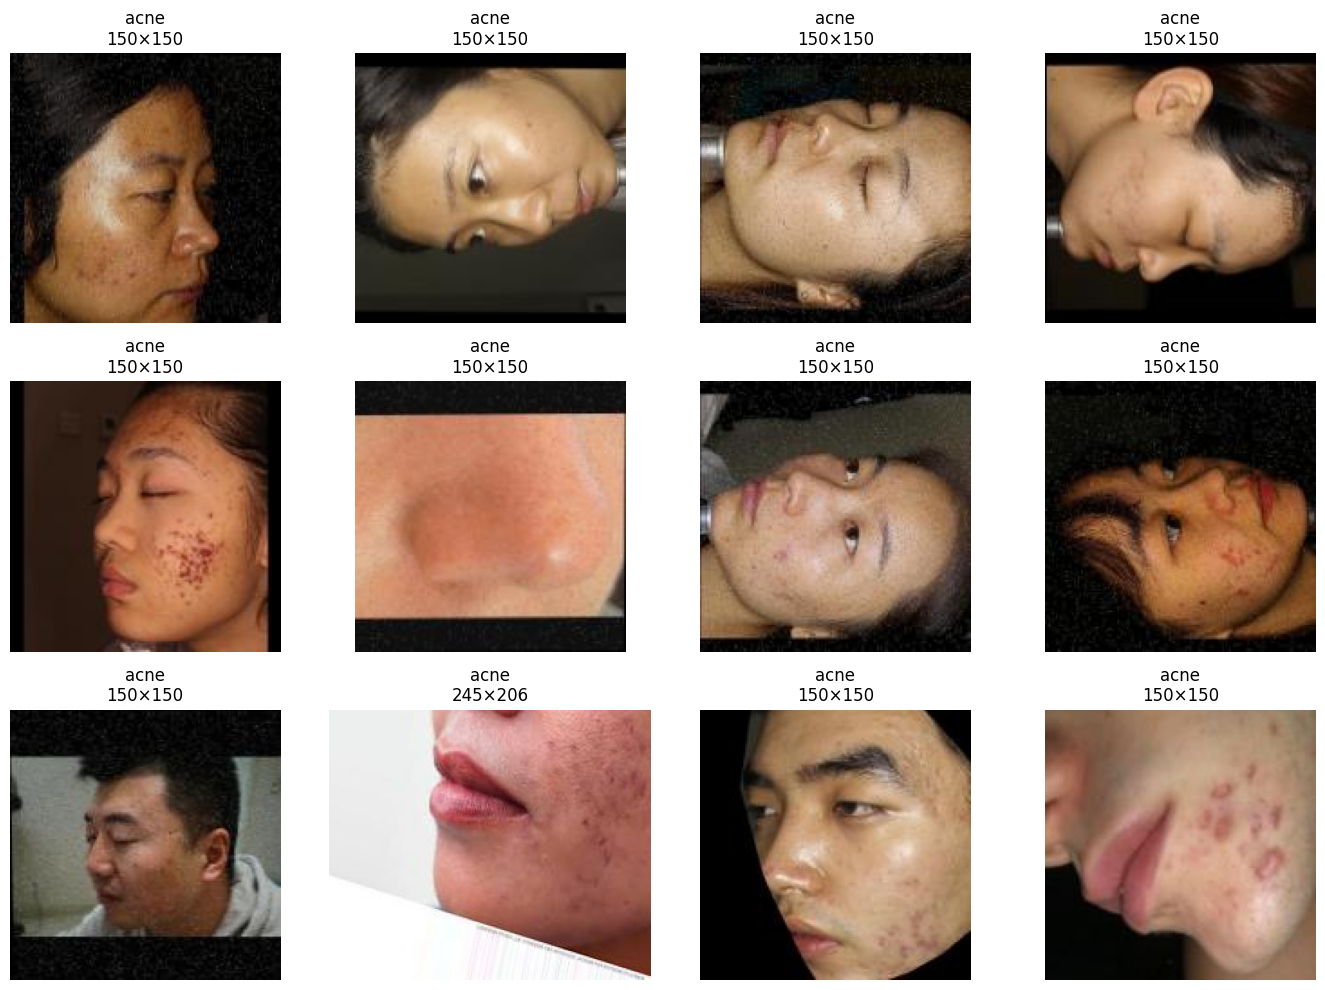

In [16]:
import matplotlib.pyplot as plt
from PIL import Image
import random

def show_low_res_samples(class_name, n=12):

    samples = low_res[
        low_res["class"] == class_name
    ].sample(
        min(n, len(low_res[low_res["class"] == class_name])),
        random_state=42
    )

    fig, axes = plt.subplots(3, 4, figsize=(14, 10))
    axes = axes.flatten()

    for ax, (_, row) in zip(axes, samples.iterrows()):

        path = Path(row["file"])

        # file column contains only filename,
        # so locate it from image_paths
        matches = [
            p for p in image_paths
            if p.name == row["file"]
            and p.parent.name == class_name
        ]

        if matches:
            img = Image.open(matches[0]).convert("RGB")
            ax.imshow(img)

        ax.set_title(
            f"{class_name}\n{row['width']}×{row['height']}"
        )
        ax.axis("off")

    for ax in axes[len(samples):]:
        ax.axis("off")

    plt.tight_layout()
    plt.show()


show_low_res_samples("acne")

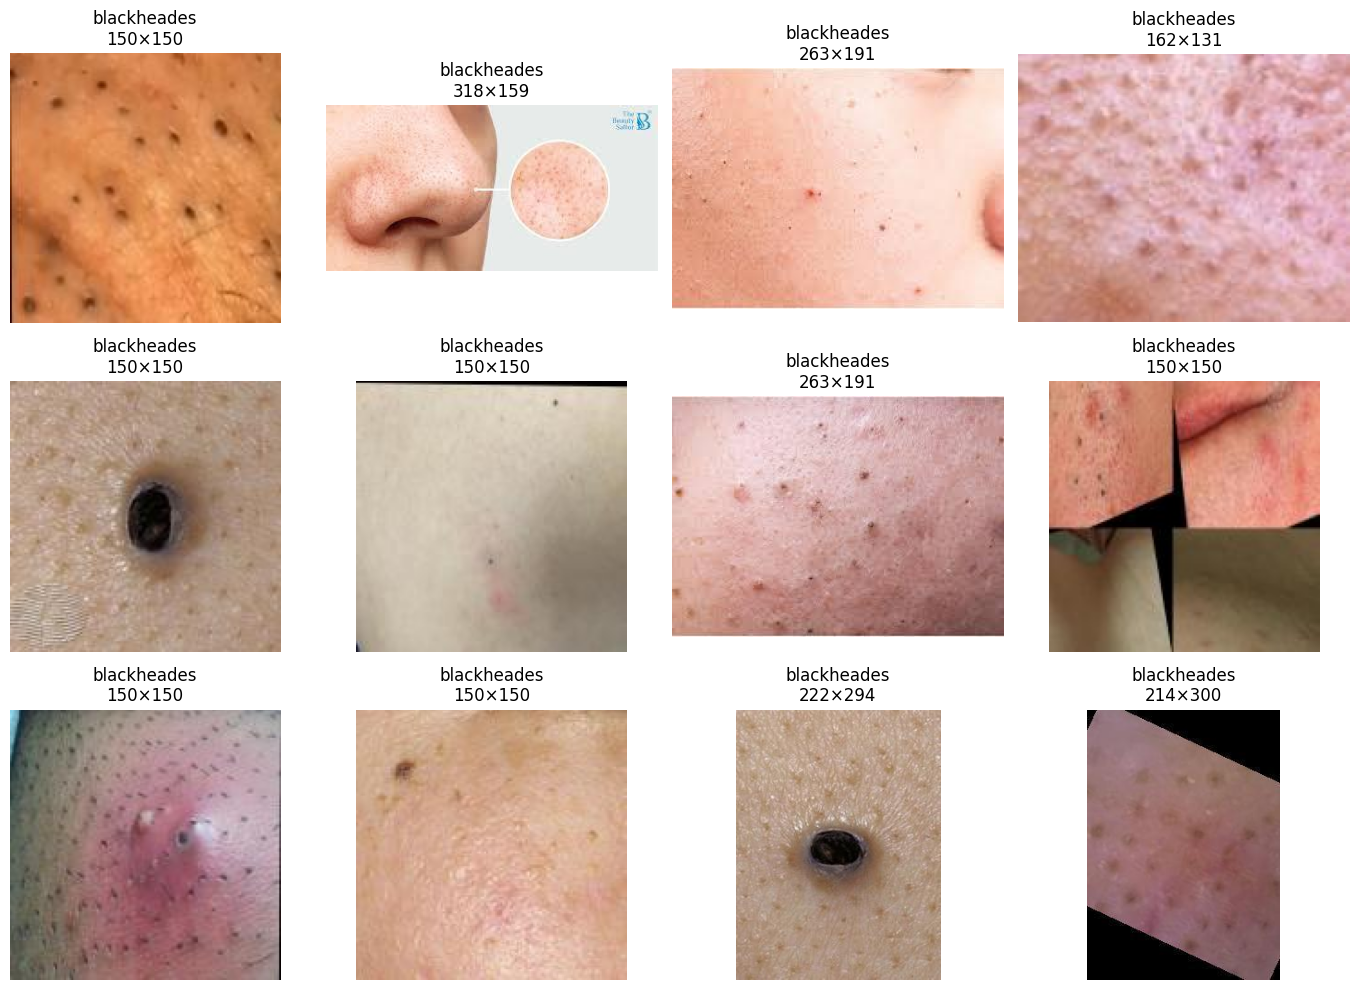

In [17]:
show_low_res_samples("blackheades")

# class-level quality analysis

In [18]:
print("CLASS-WISE QUALITY SUMMARY")
print("=" * 70)

class_quality = quality_df.groupby("class").agg(
    images=("class", "count"),
    avg_brightness=("brightness", "mean"),
    avg_contrast=("contrast", "mean"),
    avg_sharpness=("laplacian_var", "mean"),
    median_sharpness=("laplacian_var", "median")
).round(2)

print(class_quality)

CLASS-WISE QUALITY SUMMARY
             images  avg_brightness  avg_contrast  avg_sharpness  \
class                                                              
acne           2060      115.230003     54.730000     102.519997   
blackheades    1970      148.199997     44.130001     137.130005   
dark spots     2126      114.400002     60.119999     215.220001   
pores          1632      156.250000     57.860001     184.779999   
wrinkles       1982      127.160004     60.340000     258.850006   

             median_sharpness  
class                          
acne                81.699997  
blackheades         93.980003  
dark spots         183.600006  
pores              182.369995  
wrinkles           235.940002  


In [19]:
print("\nLOW-QUALITY OUTLIERS BY CLASS")
print("=" * 70)

for cls in quality_df["class"].unique():

    subset = quality_df[quality_df["class"] == cls]

    dark = (subset["brightness"] < 40).sum()
    bright = (subset["brightness"] > 220).sum()
    low_contrast = (subset["contrast"] < 20).sum()
    blurry = (subset["laplacian_var"] < 10).sum()

    print(f"\n{cls}")
    print(f"  Very dark:       {dark}")
    print(f"  Very bright:     {bright}")
    print(f"  Low contrast:    {low_contrast}")
    print(f"  Potential blur:  {blurry}")


LOW-QUALITY OUTLIERS BY CLASS

acne
  Very dark:       7
  Very bright:     0
  Low contrast:    1
  Potential blur:  7

dark spots
  Very dark:       0
  Very bright:     0
  Low contrast:    0
  Potential blur:  1

wrinkles
  Very dark:       12
  Very bright:     5
  Low contrast:    0
  Potential blur:  0

pores
  Very dark:       0
  Very bright:     0
  Low contrast:    0
  Potential blur:  2

blackheades
  Very dark:       4
  Very bright:     15
  Low contrast:    22
  Potential blur:  31


In [20]:
from collections import defaultdict
from pathlib import Path

# quality_df contains file names and class names
# We need the pHash information from the previous pHash analysis.
# This assumes your previous pHash dictionary is called `hash_records`.

print("Available variables containing 'hash':")
print([x for x in globals() if "hash" in x.lower()])

Available variables containing 'hash':
['hashlib', 'hash_groups', 'imagehash', 'phash_groups', 'unique_phashes', 'phash_duplicate_groups', 'images_in_phash_groups']


In [21]:
print("Type:", type(phash_duplicate_groups))
print("Number of groups:", len(phash_duplicate_groups))

print("\nFirst group:")
print(phash_duplicate_groups[0] if isinstance(phash_duplicate_groups, list)
      else next(iter(phash_duplicate_groups.items())))

Type: <class 'dict'>
Number of groups: 1651

First group:
('952a6ac995b1376a', ['/kaggle/input/datasets/drishyatomar/glowmix-merged-facial-skincare-dataset/Skin Issues Dataset/Skin v2/acne/acne-open-comedo-34_jpg.rf.31b9f07e778622f124446f510632bbe2.jpg', '/kaggle/input/datasets/drishyatomar/glowmix-merged-facial-skincare-dataset/Skin Issues Dataset/Skin v2/blackheades/acne-open-comedo-34_jpg.rf.4f8d54dd9907bfbc86a56dc116de80c4.jpg'])


In [22]:
from collections import Counter
from pathlib import Path

cross_class_groups = []

for phash, paths in phash_duplicate_groups.items():

    classes = [Path(p).parent.name for p in paths]

    if len(set(classes)) > 1:
        cross_class_groups.append(
            (phash, paths, classes)
        )

print("Cross-class repeated pHash groups:", len(cross_class_groups))

print("\nFirst 20:")
for i, (phash, paths, classes) in enumerate(cross_class_groups[:20], 1):

    print(f"\nGroup {i}")
    print("pHash:", phash)

    for path, cls in zip(paths, classes):
        print(f"  [{cls}] {Path(path).name}")

Cross-class repeated pHash groups: 26

First 20:

Group 1
pHash: 952a6ac995b1376a
  [acne] acne-open-comedo-34_jpg.rf.31b9f07e778622f124446f510632bbe2.jpg
  [blackheades] acne-open-comedo-34_jpg.rf.4f8d54dd9907bfbc86a56dc116de80c4.jpg

Group 2
pHash: da8505de96e599a4
  [acne] acne-open-comedo-37_jpg.rf.b8bdcac9118041b0831d4d39cb29f9c5.jpg
  [blackheades] acne-open-comedo-37_jpg.rf.98f8380e9254639bb98c93e51fb13714.jpg

Group 3
pHash: d526756c8cd9cc8c
  [acne] acne-open-comedo-68_jpg.rf.060dadca4ed4825af33e835a94861f7f.jpg
  [blackheades] acne-open-comedo-68_jpg.rf.786d95b75b7d638605e3eddccc9fb102.jpg
  [blackheades] acne-191_jpg.rf.8a761c2f1bb1b3413194f759a98c7dc2.jpg

Group 4
pHash: 90ff4720c6383fc6
  [acne] OIP-30-_jpg.rf.7481d50b0a02588c437e5d4ba56fafcd.jpg
  [blackheades] 142_jpg.rf.f1a2651512c48946a4be75f4c65597c1.jpg

Group 5
pHash: c234356b21fa56b5
  [acne] acne-open-comedo-23_jpg.rf.955f08a386e1347c8f9fa28afc3d001b.jpg
  [blackheades] acne-open-comedo-23_jpg.rf.9e14602442de4a42e

In [26]:
from PIL import Image
import matplotlib.pyplot as plt
from pathlib import Path

phash, paths, classes = cross_class_groups[0]

print("pHash:", phash)

for path, cls in zip(paths, classes):
    print(cls, Path(path).name)

    img = Image.open(path).convert("RGB")
    print("Size:", img.size)

pHash: 952a6ac995b1376a
acne acne-open-comedo-34_jpg.rf.31b9f07e778622f124446f510632bbe2.jpg
Size: (470, 720)
blackheades acne-open-comedo-34_jpg.rf.4f8d54dd9907bfbc86a56dc116de80c4.jpg
Size: (416, 416)


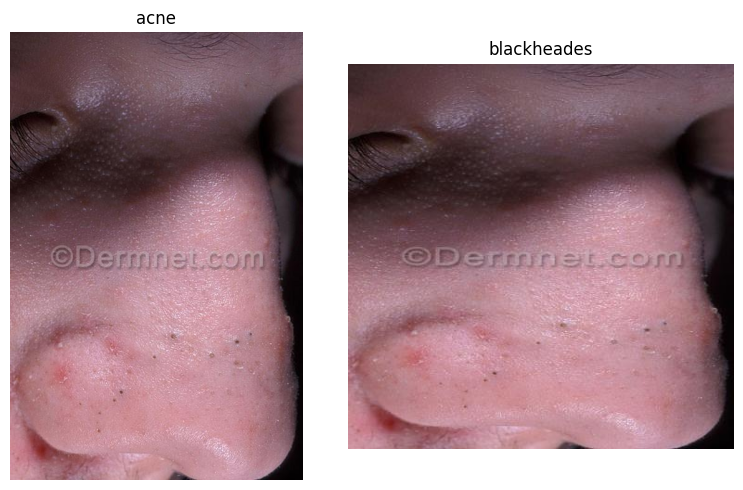

In [27]:
from PIL import Image
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(8, 5))

for ax, path, cls in zip(axes, paths, classes):
    img = Image.open(path).convert("RGB")
    ax.imshow(img)
    ax.set_title(cls)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [30]:
for i, (phash, paths, classes) in enumerate(cross_class_groups, 1):
    print(f"\nGROUP {i} | {phash}")
    for path, cls in zip(paths, classes):
        print(f"  {cls}: {path.split('/')[-1]}")


GROUP 1 | 952a6ac995b1376a
  acne: acne-open-comedo-34_jpg.rf.31b9f07e778622f124446f510632bbe2.jpg
  blackheades: acne-open-comedo-34_jpg.rf.4f8d54dd9907bfbc86a56dc116de80c4.jpg

GROUP 2 | da8505de96e599a4
  acne: acne-open-comedo-37_jpg.rf.b8bdcac9118041b0831d4d39cb29f9c5.jpg
  blackheades: acne-open-comedo-37_jpg.rf.98f8380e9254639bb98c93e51fb13714.jpg

GROUP 3 | d526756c8cd9cc8c
  acne: acne-open-comedo-68_jpg.rf.060dadca4ed4825af33e835a94861f7f.jpg
  blackheades: acne-open-comedo-68_jpg.rf.786d95b75b7d638605e3eddccc9fb102.jpg
  blackheades: acne-191_jpg.rf.8a761c2f1bb1b3413194f759a98c7dc2.jpg

GROUP 4 | 90ff4720c6383fc6
  acne: OIP-30-_jpg.rf.7481d50b0a02588c437e5d4ba56fafcd.jpg
  blackheades: 142_jpg.rf.f1a2651512c48946a4be75f4c65597c1.jpg

GROUP 5 | c234356b21fa56b5
  acne: acne-open-comedo-23_jpg.rf.955f08a386e1347c8f9fa28afc3d001b.jpg
  blackheades: acne-open-comedo-23_jpg.rf.9e14602442de4a42ee7851833561ea41.jpg

GROUP 6 | c5d12e817d07e45b
  acne: acne-open-comedo-4_jpg.rf.02e

In [31]:
# Calculate all images involved in cross-class pHash groups

cross_class_images = set()

for phash, paths, classes in cross_class_groups:
    for path in paths:
        cross_class_images.add(path)

print("Cross-class pHash groups :", len(cross_class_groups))
print("Images involved          :", len(cross_class_images))

# Count by class
from collections import Counter
class_counts = Counter()

for phash, paths, classes in cross_class_groups:
    for path, cls in zip(paths, classes):
        class_counts[cls] += 1

print("\nImages by class occurrence:")
for cls, count in class_counts.most_common():
    print(f"{cls:20s}: {count}")

Cross-class pHash groups : 26
Images involved          : 56

Images by class occurrence:
blackheades         : 28
acne                : 25
pores               : 2
dark spots          : 1


In [33]:
# Unique image paths by class involved in cross-class groups

unique_class_images = {}

for cls in class_counts:
    unique_class_images[cls] = set()

for phash, paths, classes in cross_class_groups:
    for path, cls in zip(paths, classes):
        unique_class_images[cls].add(path)

print("\nUnique affected images by class:")
for cls, paths in unique_class_images.items():
    print(f"{cls:20s}: {len(paths)}")


Unique affected images by class:
acne                : 25
blackheades         : 28
dark spots          : 1
pores               : 2
